In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [3]:
df = pd.read_csv("../data/raw/fire_incident_data.csv")

df.head()

C:\Users\BSE\AppData\Local\Temp\ipykernel_27816\1450533869.py:1: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/raw/fire_incident_data.csv")


,_id,Incident_Number,Initial_CAD_Event_Type,Final_Incident_Type,Exposures,Incident_Station_Area,Incident_Ward,Intersection,Latitude,Longitude,Property_Use,Building_Status,TFS_Alarm_Time,TFS_Arrival_Time,Ext_agent_app_or_defer_time,Fire_Under_Control_Time,Last_TFS_Unit_Clear_Time,Number_of_responding_apparatus,Number_of_responding_personnel,Count_of_Persons_Rescued,TFS_Firefighter_Casualties,Civilian_Casualties,Estimated_Number_Of_Persons_Displaced,Estimated_Dollar_Loss,Business_Impact,Status_of_Fire_On_Arrival,Method_Of_Fire_Control,Area_of_Origin,Level_Of_Origin,Extent_Of_Fire,Smoke_Spread,Ignition_Source,Material_First_Ignited,Possible_Cause,Smoke_Alarm_at_Fire_Origin,Smoke_Alarm_at_Fire_Origin_Alarm_Failure,Smoke_Alarm_at_Fire_Origin_Alarm_Type,Smoke_Alarm_Impact_on_Persons_Evacuating_Impact_on_Evacuation,Fire_Alarm_System_Presence,Fire_Alarm_System_Operation,Fire_Alarm_System_Impact_on_Evacuation,Sprinkler_System_Presence,Sprinkler_System_Operation
0,1,F18020956,Vehicle Fire,01 - Fire,NaN,441,1.0,Dixon Rd / 427 N Dixon Ramp,43.686558,-79.599419,"896 - Sidewalk, street, roadway, highway, hwy ...",NaN,2018-02-24T21:04:29,2018-02-24T21:10:11,2018-02-24T21:12:00,2018-02-24T21:15:40,2018-02-24T21:38:31,1.0,4.0,0.0,0.0,0.0,NaN,15000.0,NaN,"7 - Fully involved (total structure, vehicle, ...",1 - Extinguished by fire department,81 - Engine Area,NaN,NaN,NaN,999 - Undetermined,47 - Vehicle,99 - Undetermined,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,F18020969,Fire - Grass/Rubbish,01 - Fire,NaN,116,18.0,Sheppard Ave E / Clairtrell Rd,43.766135,-79.390039,"896 - Sidewalk, street, roadway, highway, hwy ...",NaN,2018-02-24T21:24:43,2018-02-24T21:29:31,2018-02-24T21:29:42,2018-02-24T21:32:24,2018-02-24T21:35:58,1.0,4.0,0.0,0.0,0.0,NaN,50.0,NaN,2 - Fire with no evidence from street,1 - Extinguished by fire department,"75 - Trash, rubbish area (outside)",NaN,NaN,NaN,999 - Undetermined,97 - Other,03 - Suspected Vandalism,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,F18021182,Fire - Highrise Residential,"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vand...",NaN,221,21.0,Danforth Rd / Savarin St,43.743230,-79.245061,891 - Outdoor general auto parking,NaN,2018-02-25T13:29:59,2018-02-25T13:36:49,NaN,NaN,2018-02-25T14:14:03,6.0,22.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,F18021192,Fire - Commercial/Industrial,01 - Fire,NaN,133,5.0,Keele St / Lawrence Ave W,43.708659,-79.478062,511 - Department Store,01 - Normal (no change),2018-02-25T14:13:39,2018-02-25T14:18:07,2018-02-25T14:19:25,2018-02-25T14:20:00,2018-02-25T15:07:42,6.0,22.0,0.0,0.0,0.0,0.0,0.0,1 - No business interruption,3 - Fire with smoke showing only - including v...,1 - Extinguished by fire department,"75 - Trash, rubbish area (outside)",999,1 - Confined to object of origin,99 - Undetermined,999 - Undetermined,99 - Undetermined (formerly 98),99 - Undetermined,9 - Floor/suite of fire origin: Smoke alarm pr...,98 - Not applicable: Alarm operated OR presenc...,9 - Type undetermined,"8 - Not applicable: No alarm, no persons present",9 - Undetermined,8 - Not applicable (no system),9 - Undetermined,9 - Undetermined,8 - Not applicable - no sprinkler system present
4,5,F18021271,Fire - Residential,"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vand...",NaN,132,8.0,Replin Rd / Tapestry Lane,43.718118,-79.443184,860 - Lawn around structure,NaN,2018-02-25T18:20:43,2018-02-25T18:26:19,NaN,NaN,2018-02-25T18:34:24,6.0,22.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 36564
Number of columns: 43


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36564 entries, 0 to 36563
Data columns (total 43 columns):
 #   Column                                                         Non-Null Count  Dtype  
---  ------                                                         --------------  -----  
 0   _id                                                            36564 non-null  int64  
 1   Incident_Number                                                36564 non-null  object 
 2   Initial_CAD_Event_Type                                         36563 non-null  object 
 3   Final_Incident_Type                                            36564 non-null  object 
 4   Exposures                                                      11146 non-null  float64
 5   Incident_Station_Area                                          36563 non-null  object 
 6   Incident_Ward                                                  36406 non-null  float64
 7   Intersection                                              

In [6]:
df.isnull().sum()

_id                                                                  0
Incident_Number                                                      0
Initial_CAD_Event_Type                                               1
Final_Incident_Type                                                  0
Exposures                                                        25418
Incident_Station_Area                                                1
Incident_Ward                                                      158
Intersection                                                         2
Latitude                                                             2
Longitude                                                            2
Property_Use                                                       224
Building_Status                                                  18483
TFS_Alarm_Time                                                       0
TFS_Arrival_Time                                                     1
Ext_ag

Visualize missing values

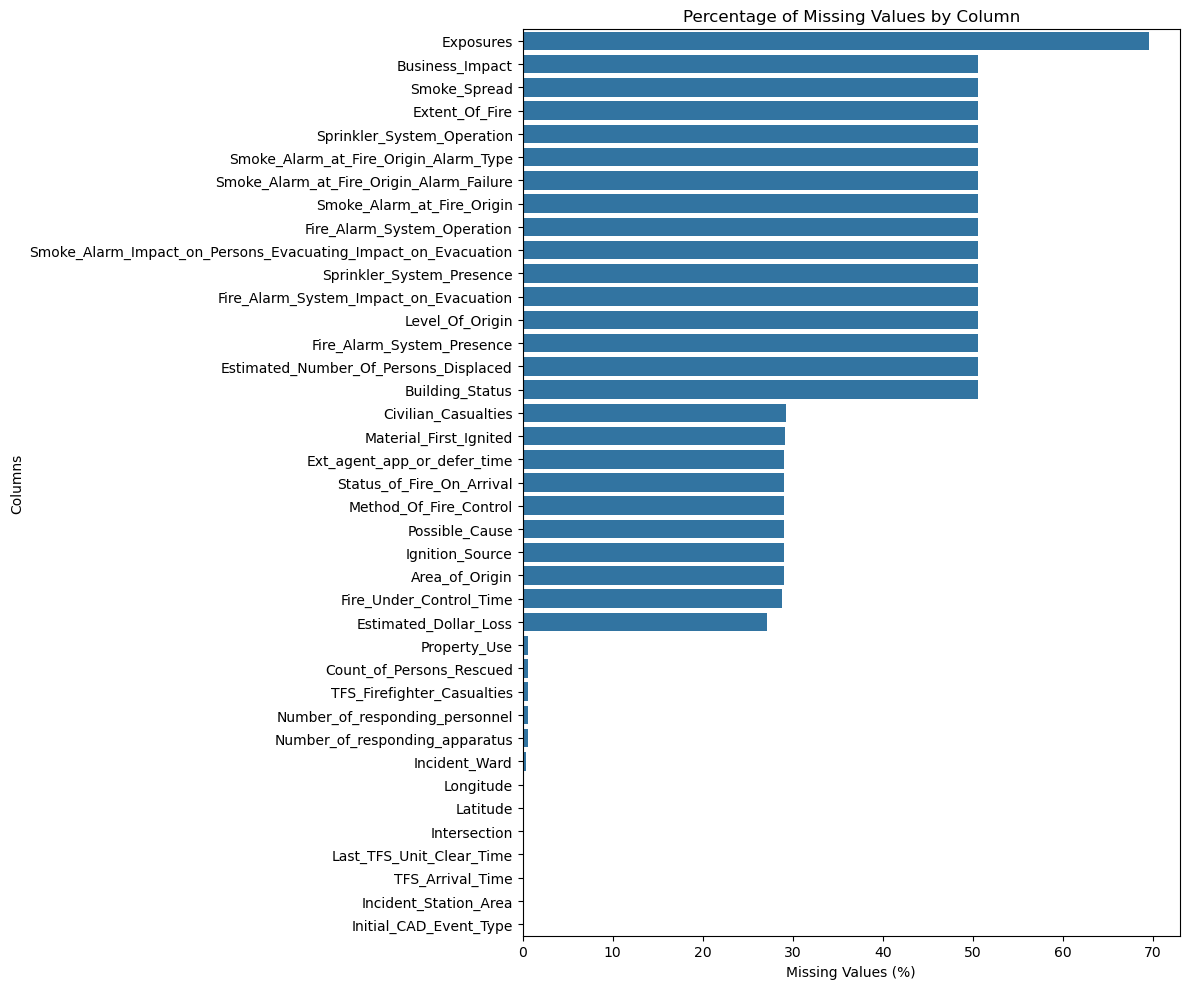

In [9]:
missing_pct = df.isnull().mean() * 100

missing_pct = missing_pct[
    missing_pct > 0
].sort_values(ascending=False)

plt.figure(figsize=(12, 10))

sns.barplot(
    x=missing_pct.values,
    y=missing_pct.index
)

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

investogate missing values by incident type

In [10]:
# Missing values by fire incident type
missing_by_type = df.groupby("Final_Incident_Type").agg(
    Total_Incidents=("Incident_Number", "size"),
    Missing_Dollar_Loss=(
        "Estimated_Dollar_Loss",
        lambda x: x.isna().sum()
    ),
    Missing_Civilian_Casualties=(
        "Civilian_Casualties",
        lambda x: x.isna().sum()
    ),
    Missing_Building_Status=(
        "Building_Status",
        lambda x: x.isna().sum()
    )
)

# Calculate missing percentages
for col in [
    "Missing_Dollar_Loss",
    "Missing_Civilian_Casualties",
    "Missing_Building_Status"
]:
    missing_by_type[col + "_Pct"] = (
        missing_by_type[col]
        / missing_by_type["Total_Incidents"] * 100
    ).round(2)

display(missing_by_type)

,Total_Incidents,Missing_Dollar_Loss,Missing_Civilian_Casualties,Missing_Building_Status,Missing_Dollar_Loss_Pct,Missing_Civilian_Casualties_Pct,Missing_Building_Status_Pct
Final_Incident_Type,,,,,,,
01 - Fire,26029,225,5864,8043,0.86,22.53,30.90
"02 - Explosion (including during Fire, excluding Codes 3 & 11-13)",151,5,26,56,3.31,17.22,37.09
"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vandal,child playing,recycling or dump fires)",10384,9685,4807,10384,93.27,46.29,100.00


Check zero and missing dollar-loss values

In [11]:
loss_summary = df.groupby("Final_Incident_Type")[
    "Estimated_Dollar_Loss"
].agg(
    Total_Records="size",
    Missing_Values=lambda x: x.isna().sum(),
    Zero_Values=lambda x: (x == 0).sum(),
    Positive_Values=lambda x: (x > 0).sum(),
    Negative_Values=lambda x: (x < 0).sum(),
    Minimum="min",
    Maximum="max"
)

display(loss_summary)

,Total_Records,Missing_Values,Zero_Values,Positive_Values,Negative_Values,Minimum,Maximum
Final_Incident_Type,,,,,,,
01 - Fire,26029,225,3122,22682,0,0.0,50000000.0
"02 - Explosion (including during Fire, excluding Codes 3 & 11-13)",151,5,29,117,0,0.0,2000000.0
"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vandal,child playing,recycling or dump fires)",10384,9685,697,2,0,0.0,135.0


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Check zero and missing civilian casualties

In [12]:
casualty_summary = df.groupby("Final_Incident_Type")[
    "Civilian_Casualties"
].agg(
    Total_Records="size",
    Missing_Values=lambda x: x.isna().sum(),
    Zero_Values=lambda x: (x == 0).sum(),
    Positive_Values=lambda x: (x > 0).sum(),
    Maximum="max"
)

display(casualty_summary)

,Total_Records,Missing_Values,Zero_Values,Positive_Values,Maximum
Final_Incident_Type,,,,,
01 - Fire,26029,5864,18743,1422,15.0
"02 - Explosion (including during Fire, excluding Codes 3 & 11-13)",151,26,102,23,2.0
"03 - NO LOSS OUTDOOR fire (exc: Sus.arson,vandal,child playing,recycling or dump fires)",10384,4807,5576,1,1.0


Check duplicate incident numbers

In [13]:
print(
    "Duplicate incident numbers:",
    df["Incident_Number"].duplicated().sum()
)

display(
    df[df["Incident_Number"].duplicated(keep=False)]
    .sort_values("Incident_Number")
    .head(10)
)

Duplicate incident numbers: 0


,_id,Incident_Number,Initial_CAD_Event_Type,Final_Incident_Type,Exposures,Incident_Station_Area,Incident_Ward,Intersection,Latitude,Longitude,Property_Use,Building_Status,TFS_Alarm_Time,TFS_Arrival_Time,Ext_agent_app_or_defer_time,Fire_Under_Control_Time,Last_TFS_Unit_Clear_Time,Number_of_responding_apparatus,Number_of_responding_personnel,Count_of_Persons_Rescued,TFS_Firefighter_Casualties,Civilian_Casualties,Estimated_Number_Of_Persons_Displaced,Estimated_Dollar_Loss,Business_Impact,Status_of_Fire_On_Arrival,Method_Of_Fire_Control,Area_of_Origin,Level_Of_Origin,Extent_Of_Fire,Smoke_Spread,Ignition_Source,Material_First_Ignited,Possible_Cause,Smoke_Alarm_at_Fire_Origin,Smoke_Alarm_at_Fire_Origin_Alarm_Failure,Smoke_Alarm_at_Fire_Origin_Alarm_Type,Smoke_Alarm_Impact_on_Persons_Evacuating_Impact_on_Evacuation,Fire_Alarm_System_Presence,Fire_Alarm_System_Operation,Fire_Alarm_System_Impact_on_Evacuation,Sprinkler_System_Presence,Sprinkler_System_Operation


In [8]:
df.describe()

,_id,Exposures,Incident_Ward,Latitude,Longitude,Number_of_responding_apparatus,Number_of_responding_personnel,Count_of_Persons_Rescued,TFS_Firefighter_Casualties,Civilian_Casualties,Estimated_Number_Of_Persons_Displaced,Estimated_Dollar_Loss
count,36564.000000,11146.000000,36406.000000,36562.000000,36562.000000,36342.000000,36342.000000,36341.000000,36342.000000,25867.000000,18079.000000,2.664900e+04
mean,18282.500000,0.075543,14.992529,43.701078,-79.394602,6.288289,21.118100,0.039294,0.009521,0.072718,15.913657,3.746614e+04
std,10555.261958,0.388991,10.093503,0.399441,0.726521,7.446613,23.437317,0.938504,0.116202,0.357953,115.058220,3.800922e+05
min,1.000000,0.000000,0.000000,0.000000,-79.639460,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00
25%,9141.750000,0.000000,7.000000,43.660175,-79.477823,1.000000,4.000000,0.000000,0.000000,0.000000,0.000000,3.000000e+02
50%,18282.500000,0.000000,13.000000,43.696814,-79.399203,5.000000,18.000000,0.000000,0.000000,0.000000,0.000000,3.000000e+03
75%,27423.250000,0.000000,21.000000,43.749175,-79.337317,8.000000,26.000000,0.000000,0.000000,0.000000,1.000000,2.000000e+04
max,36564.000000,7.000000,44.000000,43.855400,0.000000,436.000000,1275.000000,86.000000,4.000000,15.000000,999.000000,5.000000e+07
